# 07 · Forecast error analysis and development candidates

**Questions:** Where do existing forecasts lose to the seasonal baseline? Is underprediction shared
with the baseline? Which side of the interval misses? Can a seasonal-anchored candidate improve an
earlier development replay without changing the existing November registrations?

This notebook has two separate purposes. Sections 1-5 diagnose already-examined 2026 outcomes;
those findings are explanatory and exploratory. Sections 6-9 restrict all candidate training, selection,
calibration and assessment data to **2025**. The candidate design was motivated by the later error
analysis, so the earlier replay is also retrospective development, not a new independent test.

No source refresh, future registration, old prediction replacement or operational model promotion
occurs here. Existing forecast products, notebooks 05/06 and both November registrations are
fingerprinted before work and checked again at the end.

In [1]:
from pathlib import Path
import sys,json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'scripts/forecast_error_analysis.py').exists())
sys.path.insert(0,str(ROOT/'scripts'))
from forecasting import load_inputs,make_examples,metrics,sha256,issue_cutoff
from forecast_intervals import load_snapshot,monitoring_view,calibrate,apply_intervals,interval_metrics
from forecast_error_analysis import (CANDIDATES,paired_errors,grouped_errors,
    development_backtest,calibrate_signed,signed_intervals,ANCHOR_FLOOR,RATIO_FEATURES)
BASE=ROOT/'data/processed/new_york'
FOLLOW=BASE/'forecasting_followup'
OUT=BASE/'forecast_error_analysis'
REPORT=ROOT/'reports/forecast_error_analysis'
OUT.mkdir(parents=True,exist_ok=True)
(REPORT/'figures').mkdir(parents=True,exist_ok=True)
protected_paths=[p for folder in ['forecasting','forecasting_followup','prospective_registry']
                 for p in (BASE/folder).rglob('*') if p.is_file()]
protected_paths += [ROOT/'notebooks/new_york'/name for name in ['05_demand_forecasting.ipynb','06_forecast_validation.ipynb']]
protected={p.relative_to(ROOT).as_posix():sha256(p) for p in protected_paths}
follow_manifest=json.loads((FOLLOW/'followup_manifest.json').read_text())
for name,item in follow_manifest['products'].items():
    assert sha256(FOLLOW/f'{name}.csv')==item['sha256']
original,routes=load_inputs(ROOT)
snapshot=follow_manifest['summary']['snapshot']
latest,poll=load_snapshot(ROOT,snapshot)
combined,_=monitoring_view(original,latest,routes)
def read_predictions(path):
    return pd.read_csv(path,dtype={'bus_route':'string'},parse_dates=['payment_date','origin'])
follow_predictions=read_predictions(FOLLOW/'evaluation_predictions.csv')
legacy_predictions=read_predictions(BASE/'forecasting/test_predictions.csv')
october_predictions=read_predictions(FOLLOW/'later_outcome_predictions.csv')
follow_model=follow_manifest['summary']['selected_model']
legacy_manifest=json.loads((BASE/'forecasting/forecast_manifest.json').read_text())
legacy_model=legacy_manifest['summary']['selected_model']
baseline='seasonal_mean4'
print('Protected files:',len(protected),'| routes:',len(routes))
display(pd.DataFrame([{'protocol':'Notebook 05 test','model':legacy_model,'delay_days':7,'route_dates':int(legacy_predictions.groupby('model').size().min())},
    {'protocol':'Notebook 06 evaluation','model':follow_model,'delay_days':14,'route_dates':int(follow_predictions.groupby('model').size().min())},
    {'protocol':'Preserved October outlook','model':legacy_model,'delay_days':7,'route_dates':int(october_predictions.groupby('model').size().min())}]))

Protected files: 44 | routes: 41


,protocol,model,delay_days,route_dates
0,Notebook 05 test,boosted_31,7,2255
1,Notebook 06 evaluation,boosted_15,14,861
2,Preserved October outlook,boosted_31,7,287


## 1. Separate protocols before interpreting errors

The older 31-leaf model, newer 15-leaf model, availability rules and evaluation periods differ.
Compare each against its baseline on its own identical route/date population. Do not pool scores
or attribute a difference between these experiments to one modelling change. Positive error means
overprediction; negative error means underprediction. Real zero targets remain in all calculations.

In [2]:
legacy_pairs=paired_errors(legacy_predictions,legacy_model,baseline)
pairs=paired_errors(follow_predictions,follow_model,baseline)
october_pairs=paired_errors(october_predictions,legacy_model,baseline)
protocol_scores=[]
for name,table in [('legacy_test',legacy_predictions),('maturity14_evaluation',follow_predictions),('later_october',october_predictions)]:
    score=metrics(table);score['protocol']=name
    protocol_scores.append(score)
protocol_scores=pd.concat(protocol_scores,ignore_index=True)
display(protocol_scores[['protocol','model','rows','mae','wape','bias']].round(3))
print('October model bias as share of actual total:',round(100*october_pairs.error_model.sum()/october_pairs.actual.sum(),2),'%')

,protocol,model,rows,mae,wape,bias
0,legacy_test,boosted_31,2255,615.055,0.113,-90.219
1,legacy_test,seasonal_latest,2255,698.224,0.128,-105.221
2,legacy_test,seasonal_mean4,2255,630.779,0.116,-152.237
3,maturity14_evaluation,boosted_15,861,903.435,0.156,-554.698
4,maturity14_evaluation,seasonal_mean4,861,1008.428,0.174,-572.459
5,later_october,boosted_31,287,1038.439,0.167,-990.425
6,later_october,seasonal_mean4,287,682.401,0.109,-568.747


October model bias as share of actual total: -15.88 %


## 2. Which routes account for gains and losses?

Excess absolute error is model error minus baseline error on the same rows. A positive total
identifies where the model loses. Separate that comparison from the largest absolute misses:
a route may be hard for both approaches while the model still improves on the baseline.
These are demand-prediction diagnostics, not labels of route efficiency.

In [3]:
route_errors=grouped_errors(pairs,['bus_route']).sort_values('excess_absolute_error',ascending=False)
october_route_errors=grouped_errors(october_pairs,['bus_route']).sort_values('excess_absolute_error',ascending=False)
route_counts=[]
for name,part in [('legacy_test',legacy_pairs),('maturity14_evaluation',pairs),('later_october',october_pairs)]:
    table=grouped_errors(part,['bus_route'])
    route_counts.append({'protocol':name,'routes':len(table),
        'model_better_routes':int(table.model_mae.lt(table.baseline_mae).sum()),
        'baseline_better_routes':int(table.model_mae.gt(table.baseline_mae).sum()),
        'ties':int(table.model_mae.eq(table.baseline_mae).sum())})
route_counts=pd.DataFrame(route_counts)
display(route_counts)
display(route_errors[['bus_route','rows','model_mae','baseline_mae','model_bias','excess_absolute_error']].head(10).round(2))
display(october_route_errors[['bus_route','rows','model_mae','baseline_mae','model_bias','excess_absolute_error']].head(10).round(2))
print('Largest model errors in maturity-14 evaluation:')
display(route_errors.sort_values('model_absolute_error',ascending=False).head(5)[['bus_route','model_absolute_error','excess_absolute_error']].round(1))

,protocol,routes,model_better_routes,baseline_better_routes,ties
0,legacy_test,41,25,16,0
1,maturity14_evaluation,41,36,5,0
2,later_october,41,2,39,0


,bus_route,rows,model_mae,baseline_mae,model_bias,excess_absolute_error
10,M125,21,657.53,621.40,-534.85,758.55
29,M55,21,196.56,173.87,97.93,476.50
34,M72,21,674.48,656.37,-487.97,380.23
24,M35,21,255.32,238.13,-89.38,361.07
27,M5,21,783.99,768.18,-534.73,332.06
1,M10,21,814.75,817.23,-581.00,-52.10
6,M106,21,311.73,316.58,-217.48,-101.79
9,M12,21,169.76,175.12,28.91,-112.66
16,M20,21,236.65,247.60,49.08,-229.79
18,M22,21,301.81,322.44,-194.92,-433.07


,bus_route,rows,model_mae,baseline_mae,model_bias,excess_absolute_error
14,M15+,7,4457.90,1934.54,-4309.24,17663.57
12,M14D+,7,3079.30,1984.11,-3079.30,7666.32
37,M86+,7,1888.27,1012.21,-1888.27,6132.42
13,M15,7,2755.22,1926.54,-2755.22,5800.76
20,M3,7,1443.88,690.71,-1443.88,5272.16
31,M60+,7,1546.48,825.93,-1546.48,5043.89
2,M101,7,2146.38,1453.11,-2061.32,4852.88
4,M103,7,1319.31,678.79,-1319.31,4483.69
0,M1,7,1540.74,935.32,-1467.98,4237.90
26,M42,7,1136.69,610.82,-1136.69,3681.07


Largest model errors in maturity-14 evaluation:


,bus_route,model_absolute_error,excess_absolute_error
14,M15+,51616.2,-10429.8
37,M86+,42748.9,-9055.4
39,M96,37394.2,-1414.0
13,M15,36441.3,-5334.6
12,M14D+,35000.9,-7118.8


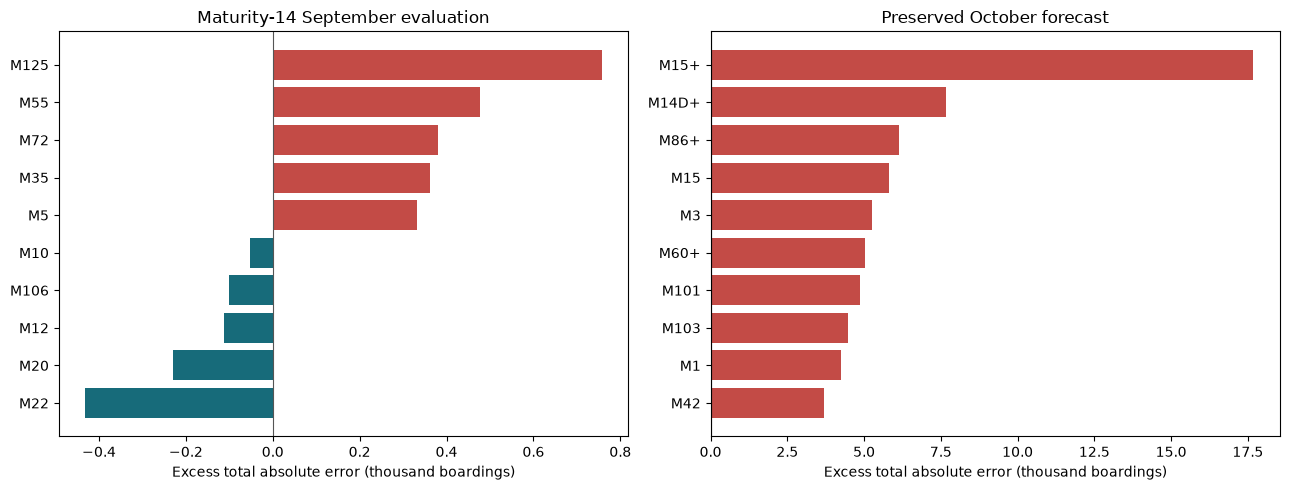

In [4]:
def save_figure(name):
    plt.tight_layout()
    plt.savefig(REPORT/'figures'/f'{name}.png',dpi=160,bbox_inches='tight')
    plt.show()
fig,axes=plt.subplots(1,2,figsize=(13,5))
for ax,table,title in [(axes[0],route_errors,'Maturity-14 September evaluation'),(axes[1],october_route_errors,'Preserved October forecast')]:
    part=table.head(10).sort_values('excess_absolute_error')
    ax.barh(part.bus_route,part.excess_absolute_error/1000,color=np.where(part.excess_absolute_error.gt(0),'#c34b46','#176b7a'))
    ax.axvline(0,color='#555555',lw=.8)
    ax.set(title=title,xlabel='Excess total absolute error (thousand boardings)')
save_figure('route_losses_against_baseline')

## 3. Weekday and issue-week patterns

Show equal-population error and signed bias. Monday-only issue dates make weekday and horizon
inseparable: a Thursday error pattern cannot establish that the fourth forecast step is intrinsically
harder. Changes over weeks are descriptive; school schedules, weather, service or reporting effects
are not measured causes in these inputs.

,weekday,rows,model_mae,baseline_mae,model_bias,baseline_bias
0,Monday,123,965.41,1275.07,-288.08,68.61
1,Tuesday,123,915.71,1016.30,-581.58,-662.29
2,Wednesday,123,941.05,1021.18,-820.97,-876.66
3,Thursday,123,1224.06,1353.08,-1114.28,-1246.74
4,Friday,123,1029.95,1149.10,-930.05,-1070.16
5,Saturday,123,789.54,808.33,-395.43,-398.33
6,Sunday,123,458.31,435.93,247.51,178.35


,origin,rows,model_mae,baseline_mae,model_bias
0,2026-09-07,287,707.26,957.00,-364.84
1,2026-09-14,287,1116.86,1193.07,-1036.77
2,2026-09-21,287,886.18,875.21,-262.48


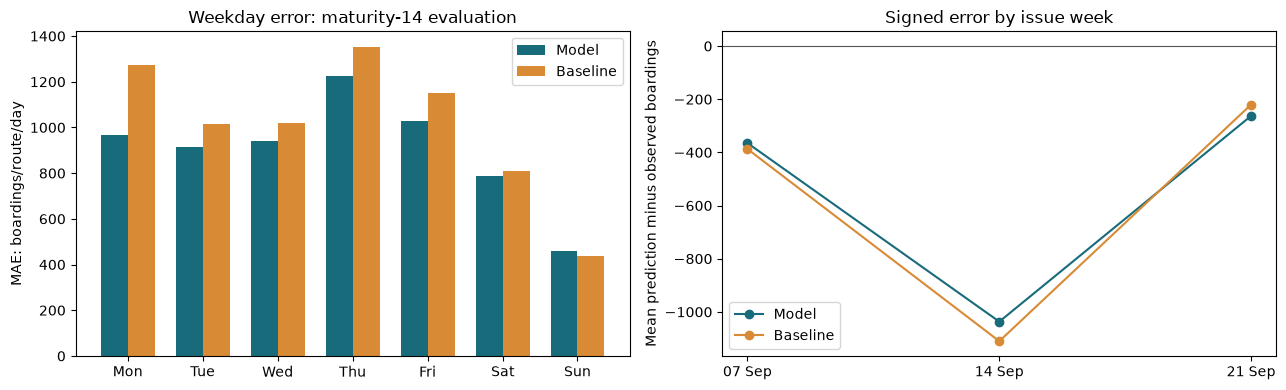

In [5]:
weekday_errors=grouped_errors(pairs,['weekday_number','weekday']).sort_values('weekday_number')
weekly_errors=grouped_errors(pairs,['origin'])
october_weekday_errors=grouped_errors(october_pairs,['weekday_number','weekday']).sort_values('weekday_number')
display(weekday_errors[['weekday','rows','model_mae','baseline_mae','model_bias','baseline_bias']].round(2))
display(weekly_errors[['origin','rows','model_mae','baseline_mae','model_bias']].round(2))
fig,axes=plt.subplots(1,2,figsize=(13,4))
x=np.arange(len(weekday_errors))
axes[0].bar(x-.18,weekday_errors.model_mae,width=.36,label='Model',color='#176b7a')
axes[0].bar(x+.18,weekday_errors.baseline_mae,width=.36,label='Baseline',color='#d98a35')
axes[0].set_xticks(x,weekday_errors.weekday.str[:3]);axes[0].set(ylabel='MAE: boardings/route/day',title='Weekday error: maturity-14 evaluation');axes[0].legend()
axes[1].plot(weekly_errors.origin,weekly_errors.model_bias,marker='o',color='#176b7a',label='Model')
axes[1].plot(weekly_errors.origin,weekly_errors.baseline_bias,marker='o',color='#d98a35',label='Baseline')
axes[1].axhline(0,color='#555555',lw=.8);axes[1].set(title='Signed error by issue week',ylabel='Mean prediction minus observed boardings');axes[1].legend()
axes[1].set_xticks(weekly_errors.origin)
axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
save_figure('weekday_and_weekly_bias')

## 4. Is error associated with realized demand growth?

Compare actual boardings with the same-weekday mean available at issuance. This ratio uses the
outcome and is **only a post-hoc diagnostic**, never a prediction feature or selection rule.
Rows with zero reference means have an undefined growth ratio and remain a separate group.
Association between growth and error is not a causal explanation of demand changes.

The plot includes a full view and an explicitly labelled 1st-99th percentile zoom. All rows
remain in the diagnostic tables and error calculations; zero-reference rows remain a separate group.

Both axes share the actual target, so their negative association is partly algebraic. This
plot is not independent evidence of drift or a causal explanation of model failure.

,growth_group,rows,model_mae,baseline_mae,model_bias,baseline_bias
0,Above reference by 10-25%,244,954.56,1063.54,-954.04,-1063.54
1,Above reference by >25%,229,1561.95,1673.01,-1561.31,-1673.01
2,Below reference by >10%,157,775.92,1047.55,745.87,1047.55
3,Undefined zero reference,3,15.11,0.00,15.11,0.00
4,Within +/-10%,228,286.82,268.28,-19.37,-64.60


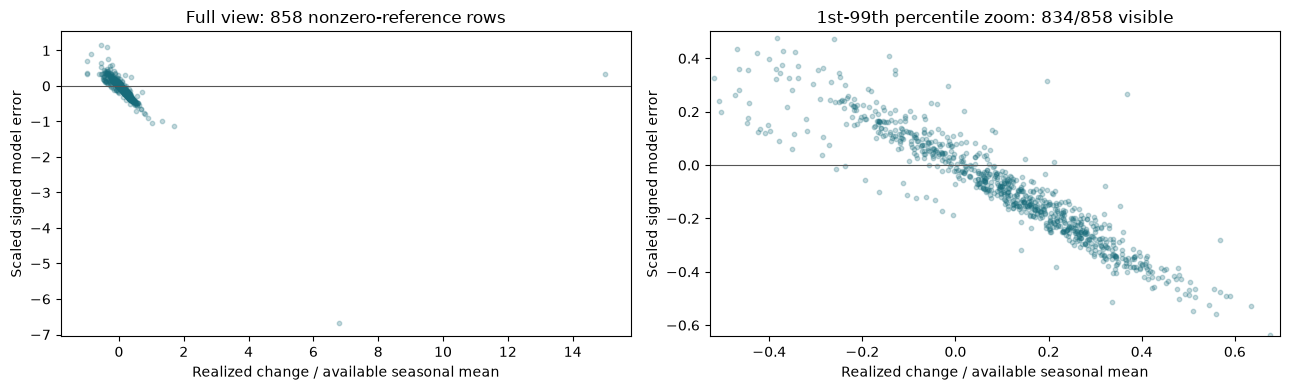

In [6]:
follow_origins=pd.DatetimeIndex(follow_predictions.origin.unique()).sort_values()
follow_examples=make_examples(combined,routes,follow_origins,14)
growth_pairs=pairs.merge(follow_examples[['bus_route','payment_date','seasonal_mean4']],on=['bus_route','payment_date'],validate='one_to_one')
growth_pairs['realized_change']=growth_pairs.actual/growth_pairs.seasonal_mean4.replace(0,np.nan)-1
growth_pairs['growth_group']=pd.cut(growth_pairs.realized_change,[-np.inf,-.1,.1,.25,np.inf],
    labels=['Below reference by >10%','Within +/-10%','Above reference by 10-25%','Above reference by >25%']).astype('string').fillna('Undefined zero reference')
growth_errors=grouped_errors(growth_pairs,['growth_group'])
display(growth_errors[['growth_group','rows','model_mae','baseline_mae','model_bias','baseline_bias']].round(2))
part=growth_pairs.loc[growth_pairs.realized_change.notna()].copy()
xvalues=part.realized_change
yvalues=part.error_model/part.seasonal_mean4.clip(lower=100)
fig,axes=plt.subplots(1,2,figsize=(13,4))
for ax in axes:
    ax.scatter(xvalues,yvalues,s=10,alpha=.25,color='#176b7a')
    ax.axhline(0,color='#555555',lw=.8)
    ax.set(xlabel='Realized change / available seasonal mean',ylabel='Scaled signed model error')
axes[0].set_title(f'Full view: {len(part)} nonzero-reference rows')
xlo,xhi=xvalues.quantile([.01,.99]);ylo,yhi=yvalues.quantile([.01,.99])
axes[1].set_xlim(xlo,xhi);axes[1].set_ylim(ylo,yhi)
visible=xvalues.between(xlo,xhi)&yvalues.between(ylo,yhi)
axes[1].set_title(f'1st-99th percentile zoom: {int(visible.sum())}/{len(part)} visible')
save_figure('realized_growth_and_error')

## 5. Why are the empirical intervals missing?

Count upper and lower misses separately. Compare scaled calibration and evaluation errors on the
same definition: absolute error divided by max(available seasonal mean, 100). A heavier evaluation
tail shows that old calibration residuals did not describe the later residual distribution. This
does not establish the underlying cause or justify widening bounds using these evaluation outcomes.

A full-range ECDF retains the extreme residuals; a second panel enlarges the region through
the larger 95th percentile. The zoom changes only the visible axes, not the plotted distributions.

,level,rows,coverage,above_upper_rate,below_lower_rate,mean_model_bias,mean_width
0,0.8,861,0.4553,0.4088,0.1359,-554.6976,1570.3565
1,0.9,861,0.6283,0.2869,0.0848,-554.6976,2247.0837


,quantile,calibration_scaled_error,evaluation_scaled_error
0,0.50,0.0738,0.1635
1,0.80,0.1500,0.2997
2,0.90,0.2148,0.3723
3,0.95,0.2949,0.4277


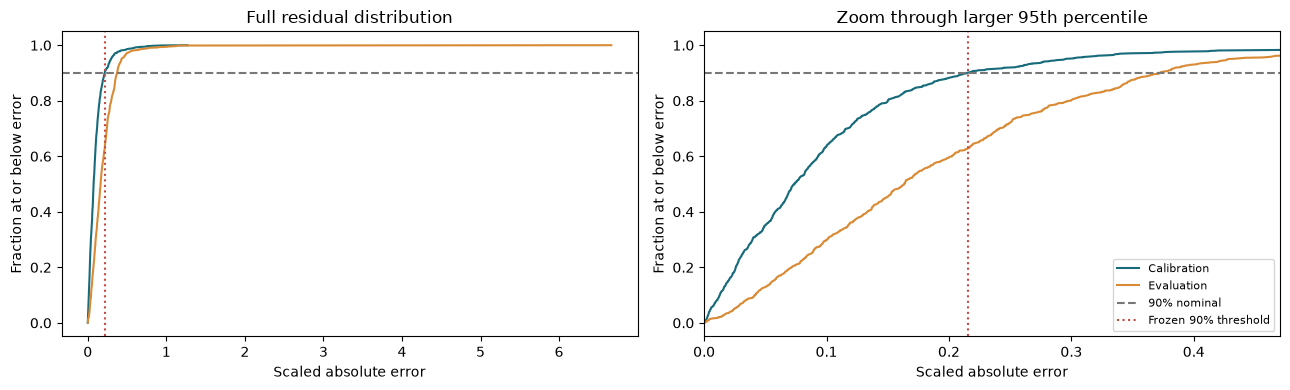

In [7]:
intervals=pd.read_csv(FOLLOW/'evaluation_intervals.csv',dtype={'bus_route':'string'},parse_dates=['payment_date','origin'])
interval_misses=[]
for level,part in intervals.groupby('level'):
    interval_misses.append({'level':level,'rows':len(part),'coverage':part.actual.between(part.lower,part.upper).mean(),
        'above_upper_rate':part.actual.gt(part.upper).mean(),'below_lower_rate':part.actual.lt(part.lower).mean(),
        'mean_model_bias':(part.prediction-part.actual).mean(),'mean_width':(part.upper-part.lower).mean()})
interval_misses=pd.DataFrame(interval_misses)
cal_preds=read_predictions(FOLLOW/'calibration_predictions.csv')
cal_examples=make_examples(combined,routes,pd.DatetimeIndex(cal_preds.origin.unique()).sort_values(),14)
cal_scores=cal_preds.merge(cal_examples[['bus_route','payment_date','seasonal_mean4']],on=['bus_route','payment_date'],validate='one_to_one')
cal_abs=(cal_scores.actual-cal_scores.prediction).abs()/cal_scores.seasonal_mean4.clip(lower=100)
eval90=intervals.loc[intervals.level.eq(.9)]
eval_abs=(eval90.actual-eval90.prediction).abs()/eval90.seasonal_mean4.clip(lower=100)
display(interval_misses.round(4))
error_quantiles=pd.DataFrame({'quantile':[.5,.8,.9,.95],
    'calibration_scaled_error':cal_abs.quantile([.5,.8,.9,.95]).to_numpy(),
    'evaluation_scaled_error':eval_abs.quantile([.5,.8,.9,.95]).to_numpy()})
display(error_quantiles.round(4))
fig,axes=plt.subplots(1,2,figsize=(13,4))
for ax in axes:
    for label,values,color in [('Calibration',cal_abs,'#176b7a'),('Evaluation',eval_abs,'#d98a35')]:
        ordered=np.sort(values.to_numpy());ax.plot(ordered,np.arange(1,len(ordered)+1)/len(ordered),label=label,color=color)
    ax.axhline(.9,color='#777777',ls='--',label='90% nominal')
    ax.axvline(follow_manifest['calibration']['levels']['0.9'],color='#c34b46',ls=':',label='Frozen 90% threshold')
    ax.set(xlabel='Scaled absolute error',ylabel='Fraction at or below error')
axes[0].set_title('Full residual distribution')
axes[1].set_xlim(0,max(cal_abs.quantile(.95),eval_abs.quantile(.95))*1.1)
axes[1].set_title('Zoom through larger 95th percentile');axes[1].legend(fontsize=8)
save_figure('calibration_distribution_shift')

## 6. Define an earlier development replay

All rows passed to this candidate experiment end **23 November 2025**. Select candidates on eight
weekly origins, 7 July-25 August (targets through 31 August). Calibrate on 15 and 22 September
(targets through 28 September). Assess on six later origins, 13 October-17 November (targets through
23 November). Selection labels are mature before calibration begins; calibration labels are mature
before assessment begins. Weekly expanding refits use a 14-complete-day holdback.

Candidates are two seasonal baselines, the fixed 15-leaf direct boosted model, an anchored ratio
model and a fixed 50/50 ratio-model/baseline blend. The ratio model predicts actual / max(seasonal
mean, 100), then converts back to boarding units using the available seasonal scale. Its predictors
are calendar, route category, log scale and normalized lag patterns. No actual target is a predictor.
Normalization changes the fitted loss emphasis; candidate selection still uses MAE in boarding units.
Both tree configurations use the existing fixed 120-iteration, 15-leaf settings. No broad tuning search.

The design responds to already-examined 2026 errors. This is development evidence, not a claim of
independent generalization. The existing November registrations remain the prospective comparison.

In [8]:
development_daily=original.loc[original.payment_date.le('2025-11-23')].copy()
development_examples=make_examples(development_daily,routes,pd.date_range('2025-03-03','2025-11-17',freq='W-MON'),14)
selection_origins=pd.date_range('2025-07-07','2025-08-25',freq='W-MON')
cal_origins=pd.date_range('2025-09-15','2025-09-22',freq='W-MON')
assessment_origins=pd.date_range('2025-10-13','2025-11-17',freq='W-MON')
assert development_examples.payment_date.max()<pd.Timestamp('2026-01-01')
assert selection_origins.max()+pd.Timedelta(days=6)<=issue_cutoff(cal_origins.min(),14)
assert cal_origins.max()+pd.Timedelta(days=6)<=issue_cutoff(assessment_origins.min(),14)
assert development_examples.max_history_date.le(development_examples.availability_cutoff).all()
display(pd.DataFrame([{'stage':label,'first_origin':values.min(),'last_target':values.max()+pd.Timedelta(days=6),
    'first_cutoff':issue_cutoff(values.min(),14),'origins':len(values)}
    for label,values in [('selection',selection_origins),('calibration',cal_origins),('assessment',assessment_origins)]]))
print('Development-only input period:',development_daily.payment_date.min().date(),'-',development_daily.payment_date.max().date())
print('Anchored feature columns:',RATIO_FEATURES)

,stage,first_origin,last_target,first_cutoff,origins
0,selection,2025-07-07,2025-08-31,2025-06-22,8
1,calibration,2025-09-15,2025-09-28,2025-08-31,2
2,assessment,2025-10-13,2025-11-23,2025-09-28,6


Development-only input period: 2025-01-01 - 2025-11-23
Anchored feature columns: ['route_code', 'weekday', 'month', 'day_of_year_sin', 'day_of_year_cos', 'federal_holiday', 'log_seasonal_scale', 'latest_ratio', 'seasonal_cv', 'lag_ratio_1', 'lag_ratio_2', 'lag_ratio_3', 'lag_ratio_4']


In [9]:
selection_predictions,selection_audit=development_backtest(development_examples,selection_origins)
selection_scores=metrics(selection_predictions).sort_values(['mae','model']).reset_index(drop=True)
selected=selection_scores.iloc[0].model
best_baseline=selection_scores.loc[selection_scores.model.isin(['seasonal_latest','seasonal_mean4'])].iloc[0].model
display(selection_scores.round(3))
print('Candidate choice frozen before calibration and assessment:',selected)

2025-07-07: 4,592 training / 287 scored rows


2025-07-14: 4,879 training / 287 scored rows


2025-07-21: 5,166 training / 287 scored rows


2025-07-28: 5,453 training / 287 scored rows


2025-08-04: 5,740 training / 287 scored rows


2025-08-11: 6,027 training / 287 scored rows


2025-08-18: 6,314 training / 287 scored rows


2025-08-25: 6,601 training / 287 scored rows


,model,rows,routes,mae,rmse,wape,bias,actual_total
0,anchored_blend_50,2296,41,389.411,568.741,0.068,88.262,13183651.0
1,anchored_ratio_15,2296,41,406.857,594.368,0.071,98.070,13183651.0
2,seasonal_mean4,2296,41,413.648,597.506,0.072,78.455,13183651.0
3,boosted_15,2296,41,428.479,640.095,0.075,60.909,13183651.0
4,seasonal_latest,2296,41,507.233,827.719,0.088,40.002,13183651.0


Candidate choice frozen before calibration and assessment: anchored_blend_50


## 7. Freeze two interval methods before assessment

Use the same selected point predictor and the same released calibration rows for both methods.
The existing method uses symmetric absolute residuals; the new method uses separate lower and
upper quantiles of signed (actual minus prediction) residuals. Both use the same fixed seasonal
scale floor of 100 and nominal 80%/90% levels. The asymmetric method can account for calibration
bias but cannot anticipate arbitrary later drift. It need not contain a biased point prediction.
Neither method has a distribution-free guarantee with these dependent, refitted time series.
Assessment results will be reported for both; they will not be used to retune their quantiles.

In [10]:
development_calibration,development_calibration_audit=development_backtest(development_examples,cal_origins,[selected])
calibration_cutoff=issue_cutoff(assessment_origins.min(),14)
absolute_calibration=calibrate(development_calibration,development_examples,calibration_cutoff)
signed_calibration=calibrate_signed(development_calibration,development_examples,calibration_cutoff)
display(pd.DataFrame([{'method':'absolute','calibration_rows':absolute_calibration['rows'],'last_target':absolute_calibration['last_calibration_target'],'cutoff':absolute_calibration['cutoff']},
    {'method':'signed','calibration_rows':signed_calibration['rows'],'last_target':signed_calibration['last_target'],'cutoff':signed_calibration['cutoff']}]))
display(pd.DataFrame([{'level':float(level),'lower_residual_quantile':bounds[0],'upper_residual_quantile':bounds[1]}
    for level,bounds in signed_calibration['bounds'].items()]).round(4))

2025-09-15: 7,462 training / 287 scored rows


2025-09-22: 7,749 training / 287 scored rows


,method,calibration_rows,last_target,cutoff
0,absolute,574,2025-09-28,2025-09-28
1,signed,574,2025-09-28,2025-09-28


,level,lower_residual_quantile,upper_residual_quantile
0,0.8,-0.1412,0.3237
1,0.9,-0.2397,0.3895


In [11]:
assessment_predictions,assessment_audit=development_backtest(development_examples,assessment_origins)
assessment_scores=metrics(assessment_predictions).sort_values('mae').reset_index(drop=True)
assessment_selected=assessment_predictions.loc[assessment_predictions.model.eq(selected)]
absolute_intervals=apply_intervals(assessment_selected,development_examples,absolute_calibration)
absolute_intervals['interval_method']='absolute'
asymmetric_intervals=signed_intervals(assessment_selected,development_examples,signed_calibration)
asymmetric_intervals['interval_method']='signed'
development_intervals=pd.concat([absolute_intervals,asymmetric_intervals],ignore_index=True)
development_coverage=interval_metrics(development_intervals,('interval_method','level'))
assert assessment_predictions.groupby('model').size().nunique()==1
assert assessment_audit.last_training_target.le(assessment_audit.cutoff).all()
display(assessment_scores.round(3))
display(development_coverage.round(3))
selected_mae=float(assessment_scores.loc[assessment_scores.model.eq(selected),'mae'].iloc[0])
baseline_mae=float(assessment_scores.loc[assessment_scores.model.eq(best_baseline),'mae'].iloc[0])
print('Frozen selection improvement vs selection-chosen baseline:',round(100*(1-selected_mae/baseline_mae),2),'%')
print('The selected candidate is not replaced after inspecting assessment scores.')

2025-10-13: 8,610 training / 287 scored rows


2025-10-20: 8,897 training / 287 scored rows


2025-10-27: 9,184 training / 287 scored rows


2025-11-03: 9,471 training / 287 scored rows


2025-11-10: 9,758 training / 287 scored rows


2025-11-17: 10,045 training / 287 scored rows


,model,rows,routes,mae,rmse,wape,bias,actual_total
0,seasonal_mean4,1722,41,430.750,648.769,0.075,58.034,9917910.0
1,anchored_blend_50,1722,41,437.202,638.625,0.076,-2.085,9917910.0
2,boosted_15,1722,41,522.945,785.538,0.091,-168.311,9917910.0
3,anchored_ratio_15,1722,41,538.539,836.251,0.094,-62.204,9917910.0
4,seasonal_latest,1722,41,583.183,922.236,0.101,-18.145,9917910.0


,interval_method,level,rows,coverage,mean_width,mean_interval_score
0,absolute,0.8,1722,0.941,2979.197,3106.860
1,absolute,0.9,1722,0.970,4063.711,4185.431
2,signed,0.8,1722,0.884,2704.924,2992.728
3,signed,0.9,1722,0.948,3660.772,3864.946


Frozen selection improvement vs selection-chosen baseline: -1.5 %
The selected candidate is not replaced after inspecting assessment scores.


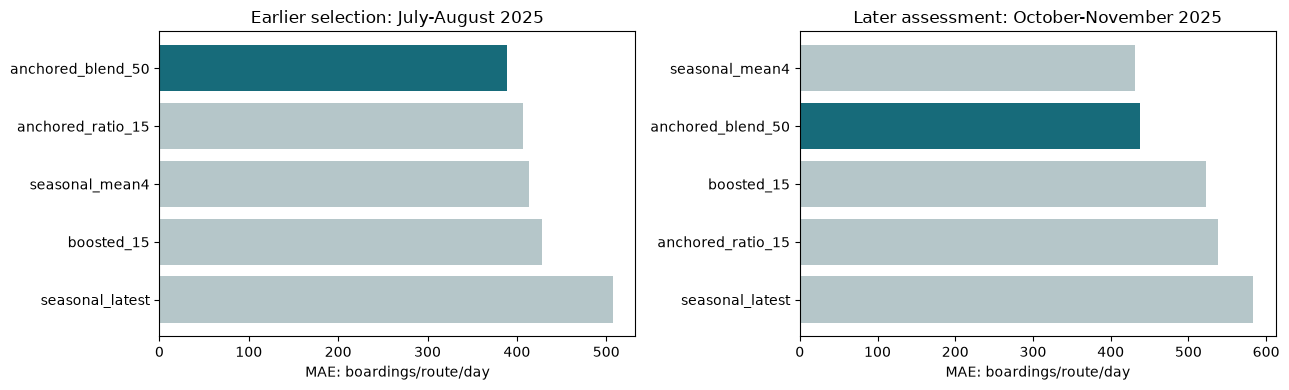

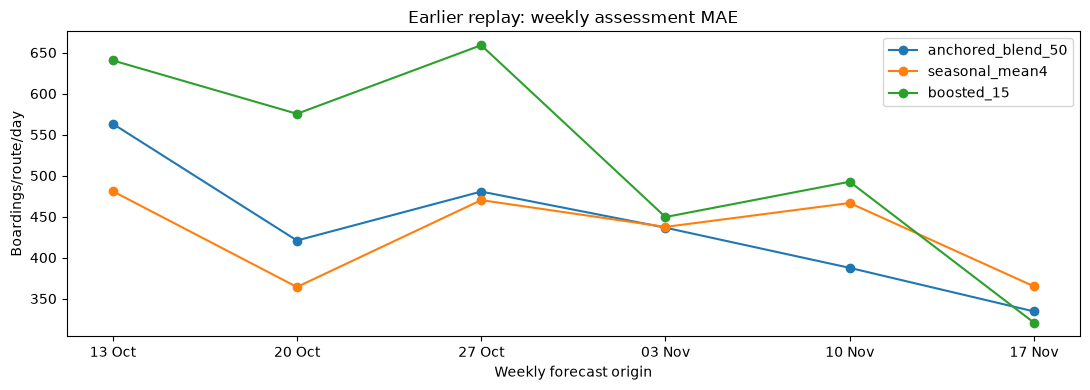

In [12]:
fig,axes=plt.subplots(1,2,figsize=(13,4))
for ax,table,title in [(axes[0],selection_scores,'Earlier selection: July-August 2025'),(axes[1],assessment_scores,'Later assessment: October-November 2025')]:
    ordered=table.sort_values('mae')
    ax.barh(ordered.model,ordered.mae,color=['#176b7a' if name==selected else '#b5c6c9' for name in ordered.model])
    ax.invert_yaxis();ax.set(title=title,xlabel='MAE: boardings/route/day')
save_figure('development_candidate_comparison')
weekly_assessment=metrics(assessment_predictions,('model','origin'))
fig,ax=plt.subplots(figsize=(11,4))
for name in dict.fromkeys([selected,best_baseline,'boosted_15']):
    part=weekly_assessment.loc[weekly_assessment.model.eq(name)]
    ax.plot(part.origin,part.mae,marker='o',label=name)
ax.set(title='Earlier replay: weekly assessment MAE',xlabel='Weekly forecast origin',ylabel='Boardings/route/day');ax.legend()
ax.set_xticks(pd.DatetimeIndex(weekly_assessment.origin.unique()).sort_values())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
save_figure('development_weekly_assessment')

## 8. Findings and improvement decisions

Separate observed facts from hypotheses. Direct-level trees may shrink large boarding predictions,
and stale seasonal history cannot observe sudden target-period changes. Neither explanation is
established as the causal source of the errors. The earlier replay tests an anchoring mechanism,
not a new operational winner. If the baseline is selected or performs better, retain that evidence.

Future steps are to evaluate the unchanged November registrations, acquire additional source
vintages, investigate route/calendar changes with independent data, and assess any revised candidate
on a newly defined future period. Do not add occupancy labels, actual delays or claimed savings.

In [13]:
miss90=interval_misses.loc[interval_misses.level.eq(.9)].iloc[0]
chosen=route_counts.loc[route_counts.protocol.eq('maturity14_evaluation')].iloc[0]
findings=pd.DataFrame([
    ['Protocol separation',f"Newer model improves on {chosen.model_better_routes}/{chosen.routes} routes in its own September window",'Cannot transfer this claim to the old October model'],
    ['Interval direction',f"{100*miss90.above_upper_rate:.2f}% above upper bound; {100*miss90.below_lower_rate:.2f}% below lower bound",'Undercoverage is asymmetric; root cause unverified'],
    ['Candidate selection',selected,'Chosen using earlier 2025 selection only'],
    ['Earlier assessment',f"Selected MAE {selected_mae:.2f}; baseline {baseline_mae:.2f}",'Retrospective development; not independent confirmation'],
    ['Prospective evaluation','Original November model and baseline registrations retained','No candidate promoted or registered here']
],columns=['topic','observation','interpretation'])
display(findings)
products={'protocol_scores':protocol_scores,'route_errors':route_errors,'october_route_errors':october_route_errors,
    'route_comparison_counts':route_counts,'weekday_errors':weekday_errors,'weekly_errors':weekly_errors,
    'october_weekday_errors':october_weekday_errors,'realized_growth_errors':growth_errors,
    'interval_miss_directions':interval_misses,'scaled_error_quantiles':error_quantiles,
    'development_selection_predictions':selection_predictions,'development_selection_scores':selection_scores,
    'development_selection_audit':selection_audit,'development_calibration_predictions':development_calibration,
    'development_calibration_audit':development_calibration_audit,'development_assessment_predictions':assessment_predictions,
    'development_assessment_scores':assessment_scores,'development_assessment_audit':assessment_audit,
    'development_intervals':development_intervals,'development_interval_coverage':development_coverage,
    'development_weekly_metrics':weekly_assessment,'findings':findings}
for name,table in products.items():table.to_csv(OUT/f'{name}.csv',index=False)
current={p.relative_to(ROOT).as_posix():sha256(p) for p in protected_paths}
assert current==protected
summary={'selected_candidate':selected,'selection_chosen_baseline':best_baseline,
    'development_input_last_date':str(development_daily.payment_date.max().date()),
    'selection_last_target':'2025-08-31','calibration_last_target':'2025-09-28',
    'assessment_first_target':'2025-10-13','assessment_last_target':'2025-11-23',
    'selected_assessment_mae':selected_mae,'baseline_assessment_mae':baseline_mae,
    'assessment_mae_improvement_percent':100*(1-selected_mae/baseline_mae),
    'assessment_scores':assessment_scores.to_dict(orient='records'),
    'assessment_interval_coverage':development_coverage.to_dict(orient='records'),
    'maturity14_routes_model_better':int(chosen.model_better_routes),
    'interval_90_above_upper_rate':float(miss90.above_upper_rate),
    'interval_90_below_lower_rate':float(miss90.below_lower_rate),
    'protected_files_verified':len(protected),'independent_confirmation':False,'candidate_promoted':False,
    'november_registrations_unchanged':True}
manifest={'summary':summary,'protected_files':protected,
    'candidate_settings':{'names':CANDIDATES,'anchor_floor':ANCHOR_FLOOR,'blend_weight':.5,
        'tree_max_iter':120,'tree_max_leaf_nodes':15,'random_state':42,'maturity_days':14},
    'absolute_calibration':absolute_calibration,'signed_calibration':signed_calibration,
    'products':{name:{'rows':len(table),'sha256':sha256(OUT/f'{name}.csv')} for name,table in products.items()}}
(OUT/'error_analysis_manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')
(REPORT/'summary.json').write_text(json.dumps(summary,indent=2),encoding='utf-8')
print('Saved',len(products),'tables and',len(list((REPORT/'figures').glob('*.png'))),'figures.')
print('All protected products, notebooks and registrations remain byte-identical.')

,topic,observation,interpretation
0,Protocol separation,Newer model improves on 36/41 routes in its ow...,Cannot transfer this claim to the old October ...
1,Interval direction,28.69% above upper bound; 8.48% below lower bound,Undercoverage is asymmetric; root cause unveri...
2,Candidate selection,anchored_blend_50,Chosen using earlier 2025 selection only
3,Earlier assessment,Selected MAE 437.20; baseline 430.75,Retrospective development; not independent con...
4,Prospective evaluation,Original November model and baseline registrat...,No candidate promoted or registered here


Saved 22 tables and 6 figures.
All protected products, notebooks and registrations remain byte-identical.


## Final interpretation

The earlier selection chose the **50/50 anchored blend**. On the later 2025 assessment its
MAE is **437.20**, compared with **522.95** for the direct model and **430.75** for the seasonal
mean baseline. Anchoring improves on the direct model here, but does not establish superiority
over the baseline. The blend is not promoted, and no registered forecast is changed.

Signed 90% residual bands achieve **94.83% coverage** with mean width **3,660.77 boardings**,
versus **97.04%** and **4,063.71** for symmetric bands. This is narrower but still overcovers;
it does not resolve the older 2026 undercoverage or demonstrate prospective reliability.

The improvement plan retains the baseline, treats anchoring and asymmetric bands as candidates,
and waits for the unchanged November registrations to receive mature outcomes. All prior
forecast products and registrations remain byte-identical. See the detailed findings in
[ERROR_ANALYSIS.md](../../documentation/ERROR_ANALYSIS.md).